### This workflow is created in the late phase of Hollowel  dataset wrangling. Before that, I have curated all problematic sequences from Hollowell 2016 S1 supplementary, checked Sanger vs NGS issues by comparing the tracer (ab1) files, and finalized a complete dataset for Bradyrhizobium including both Hollowell and Lorena's sequences.

# Create haplotype meta file

In [1]:
import pandas as pd

#init emptyHashDict

def name2dict(namesFile):
    '''
    Input: Mothur namefile in tsv format
    Output: A dictionary mapping isolate with all it\'s identical haplotype isolates
    '''
    nameDict = {}
    with open(namesFile) as f:
        data = f.readlines()
    for i in data:
        hap, mem = i.split('\t')
        mem = mem.strip().split(',')
        nameDict[hap] = mem
    return(nameDict)

def reverseNameDict(nameDict):
    '''
    Input: Output from name2dict
    Output: All isolates from name2dict output mapping to their unique haplotype isolate id
    '''
    revNameDict = {}
    for i in nameDict.keys():
        for j in nameDict[i]:
            revNameDict[j] = i
        #else:
        #   revNameDict[j] = i
    return revNameDict

def annotateHaplotype(prefix, similarity_list):
    '''
    Input: A list of unique haplotype isolate from meta haplotype matrix and a prefix for the loci
    Output: Map the provided list serially adding numbers after prefix
    '''
    count=1
    annotated = {}
    discard = []
    codedList = []
    for i in similarity_list:
        if i not in discard:            
            haplotype = prefix + str(count)
            count += 1
            discard.append(i)
            annotated[i] = haplotype
        else:
            haplotype = annotated[i]
        codedList.append(annotated[i])
    return codedList

#pd.read_csv('Bradyrhizobium/Dataset/Complete/Dataset/chr/recA.567.names', sep='\t', header=None)

In [2]:
recA_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/chr/recA.567.fasta.filter.names'))
ITS_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/chr/ITS.567.fasta.filter.names'))
glnII_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/chr/glnII.567.fasta.filter.names'))
dnaK_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/chr/dnaK.567.fasta.filter.names'))

nifD_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/sym/nifD.brady.fasta.filter.names'))
nodA_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/sym/nodA.brady.fasta.filter.names'))
nodL_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/sym/nodL.brady.fasta.filter.names'))
nodZ_names = reverseNameDict(name2dict('Bradyrhizobium/Dataset/Complete/Dataset/sym/nodZ.brady.fasta.filter.names'))

In [3]:
haplotypes = {'dnaK_similarity':dnaK_names, 'recA_similarity':recA_names, 'ITS_similarity':ITS_names, 
              'glnII_similarity':glnII_names,'nifD_similarity':nifD_names, 'nodA_similarity':nodA_names, 
              'nodL_similarity':nodL_names, 'nodZ_similarity':nodZ_names}
haplotypes = pd.DataFrame.from_dict(haplotypes)

haplotypes.index.name = 'Isolate'

conservative_haplotypes = haplotypes.dropna()
conservative_haplotypes

,dnaK_similarity,recA_similarity,ITS_similarity,glnII_similarity,nifD_similarity,nodA_similarity,nodL_similarity,nodZ_similarity
Isolate,,,,,,,,
19AcHe316.1.1,19AcHe316.1.1,19AcS397Asp.3.1,11LoS24_1,11LoS6_3,11LoS6_3,19AcGLB10.1.1,05LoS16_8,11LoS7_2
19AcS309.1.1,19AcHe316.1.1,05LoS13_4,11LoS24_1,11LoS6_3,19AcS309.1.1,19AcGLB10.1.1,19AcS309.1.1,19AcS309.1.1
19AcARN268.1.1,19AcHe316.1.1,19AcS397Asp.3.1,11LoS24_1,11LoS6_3,19AcS5.2.1,19AcS398Asp.1.1,19AcARN268.1.1,11LoS6_3
19AcS398Asp.1.1,19AcHe316.1.1,19AcS397Asp.3.1,19AcS398Asp.1.1,11LoS6_3,12LoS5_2,19AcS398Asp.1.1,05LoS22_6,11LoS6_3
19AcS307.2.1,19AcHe316.1.1,05LoS7_9,11LoS24_1,11LoS6_3,19AcS307.2.1,19AcS307.2.1,19AcS5.1.1,11LoS15_2
...,...,...,...,...,...,...,...,...
12LoS3_5,12LoS3_5,05LoS13_4,12LoS3_5,12LoS3_5,12LoS3_5,12LoS3_5,12LoS3_5,12LoS3_5
12LoS3_8,12LoS3_8,19AcS397Asp.3.1,12LoS3_8,12LoS3_8,12LoS1_4,11LoS19_4,12LoS20_5,11LoS19_4
12LoS16_3,12LoS16_3,19AcS397Asp.3.1,11LoS25_1,11LoS11_2,12LoS16_3,12LoS16_3,19AcGR302.5.1,12LoS16_3


In [4]:
annotate_dnaK = annotateHaplotype('K', list(conservative_haplotypes['dnaK_similarity']))
annotate_recA = annotateHaplotype('R', list(conservative_haplotypes['recA_similarity']))
annotate_ITS = annotateHaplotype('I', list(conservative_haplotypes['ITS_similarity']))
annotate_glnII = annotateHaplotype('G', list(conservative_haplotypes['glnII_similarity']))

annotate_nifD = annotateHaplotype('D', list(conservative_haplotypes['nifD_similarity']))
annotate_nodA = annotateHaplotype('A', list(conservative_haplotypes['nodA_similarity']))
annotate_nodL = annotateHaplotype('L', list(conservative_haplotypes['nodL_similarity']))
annotate_nodZ = annotateHaplotype('Z', list(conservative_haplotypes['nodZ_similarity']))            


conservative_haplotypes['dnaK_coded'] = annotate_dnaK
conservative_haplotypes['recA_coded'] = annotate_recA
conservative_haplotypes['ITS_coded'] = annotate_ITS
conservative_haplotypes['glnII_coded'] = annotate_glnII

conservative_haplotypes['nifD_coded'] = annotate_nifD
conservative_haplotypes['nodA_coded'] = annotate_nodA
conservative_haplotypes['nodL_coded'] = annotate_nodL
conservative_haplotypes['nodZ_coded'] = annotate_nodZ

/Users/arafat/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  if sys.path[0] == '':
/Users/arafat/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  del sys.path[0]
/Users/arafat/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

S

In [5]:
conservative_haplotypes = conservative_haplotypes[['dnaK_similarity', 'dnaK_coded', 'recA_similarity', 
                                                   'recA_coded', 'ITS_similarity', 'ITS_coded', 'glnII_similarity', 
                                                   'glnII_coded', 'nifD_similarity', 'nifD_coded', 'nodA_similarity', 
                                                   'nodA_coded', 'nodL_similarity', 'nodL_coded', 'nodZ_similarity', 
                                                   'nodZ_coded']]

## Need to incorporate site, sampling longitude and latitude coordinates, and host species from meta file

In [6]:
meta = pd.read_csv('../Metadata_Hollo.Geno.726.csv', encoding = 'latin1')
meta = meta.drop_duplicates(subset=['Strain'], keep='first')

merged_meta = pd.merge(conservative_haplotypes, meta, how='left', left_on=['Isolate'], right_on=['Strain'])

merged_meta

,dnaK_similarity,dnaK_coded,recA_similarity,recA_coded,ITS_similarity,ITS_coded,glnII_similarity,glnII_coded,nifD_similarity,nifD_coded,...,nodZ_similarity,nodZ_coded,Source,Strain,Site,Latitude,Longitude,Host,Rhizobial_lineage,ANI_species
0,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,11LoS24_1,I1,11LoS6_3,G1,11LoS6_3,D1,...,11LoS7_2,Z1,Genomes,19AcHe316.1.1,San Dimas Canyon,34.164527,-117.769316,A. heermannii,Bradyrhizobium,24.0
1,19AcHe316.1.1,K1,05LoS13_4,R2,11LoS24_1,I1,11LoS6_3,G1,19AcS309.1.1,D2,...,19AcS309.1.1,Z2,Genomes,19AcS309.1.1,Santa Cruz Island,34.005550,-119.704450,A. strigosus,Bradyrhizobium,24.0
2,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,11LoS24_1,I1,11LoS6_3,G1,19AcS5.2.1,D3,...,11LoS6_3,Z3,Genomes,19AcARN268.1.1,Santa Cruz Island,34.011410,-119.689670,A. argophyllus var. niveus,Bradyrhizobium,24.0
3,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,19AcS398Asp.1.1,I2,11LoS6_3,G1,12LoS5_2,D4,...,11LoS6_3,Z3,Genomes,19AcS398Asp.1.1,Sedgwick,34.739433,-120.026883,A. strigosus,Bradyrhizobium,24.0
4,19AcHe316.1.1,K1,05LoS7_9,R3,11LoS24_1,I1,11LoS6_3,G1,19AcS307.2.1,D5,...,11LoS15_2,Z4,Genomes,19AcS307.2.1,Santa Cruz Island,34.005550,-119.704450,A. strigosus,Bradyrhizobium,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
502,12LoS3_5,K59,05LoS13_4,R2,12LoS3_5,I91,12LoS3_5,G62,12LoS3_5,D112,...,12LoS3_5,Z92,Hollowell,12LoS3_5,San Dimas Canyon,34.134360,-117.780000,A. strigosus,Bradyrhizobium,NaN
503,12LoS3_8,K60,19AcS397Asp.3.1,R1,12LoS3_8,I92,12LoS3_8,G63,12LoS1_4,D65,...,11LoS19_4,Z35,Hollowell,12LoS3_8,San Dimas Canyon,34.134360,-117.780000,A. strigosus,Bradyrhizobium,NaN
504,12LoS16_3,K61,19AcS397Asp.3.1,R1,11LoS25_1,I31,11LoS11_2,G18,12LoS16_3,D126,...,12LoS16_3,Z93,Hollowell,12LoS16_3,Robert J. Bernard Biological Field Station,34.110390,-117.707990,A. strigosus,Bradyrhizobium,NaN
505,12LoS16_4,K62,19AcS397Asp.3.1,R1,11LoS25_1,I31,11LoS11_2,G18,12LoS16_3,D126,...,12LoS16_3,Z93,Hollowell,12LoS16_4,Robert J. Bernard Biological Field Station,34.110390,-117.707990,A. strigosus,Bradyrhizobium,NaN


In [7]:
merged_meta.to_csv('Bradyrhizobium/Dataset/Complete/Dataset/haplotype_meta.csv')

## Removing duplicate plants

In [50]:
import pandas as pd
meta = pd.read_csv('Bradyrhizobium/Dataset/Complete/Dataset/haplotype_meta.csv')

In [51]:
plant_dict = {}

for i in list(meta['Strain']):
    if '.' in i:
        plantGenotype, plantID = i.split('.')[:2]
    elif '_' in i:
        plantGenotype, plantID = i.split('_')
    if plantGenotype not in plant_dict.keys():
        plant_dict[plantGenotype] = [plantID]
    else:
        plant_dict[plantGenotype].append(plantID)

# plant_dict

In [52]:
plant_count = {'plant_genotype':[], 'nodule_no':[]}

for i in plant_dict.keys():
    plant_count['plant_genotype'].append(i)
    plant_count['nodule_no'].append(len(plant_dict[i]))

plant_count = pd.DataFrame.from_dict(plant_count)
plant_count

,plant_genotype,nodule_no
0,19AcHe316,1
1,19AcS309,1
2,19AcARN268,2
3,19AcS398Asp,2
4,19AcS307,2
...,...,...
170,13LoS16,1
171,19AcAM272,2
172,19AcAM288,2
173,19AcAm187A,1


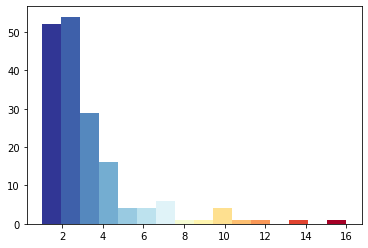

In [59]:
import matplotlib.pyplot as plt

cm = plt.cm.get_cmap('RdYlBu_r')

n, bins, patches = plt.hist(plant_count['nodule_no'], bins=16)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

# scale values to interval [0,1]
col = bin_centers - min(bin_centers)
col /= max(col)

for c, p in zip(col, patches):
    plt.setp(p, 'facecolor', cm(c))

plt.show()

In [68]:
meta[0:5]

,Strain,dnaK_similarity,dnaK_coded,recA_similarity,recA_coded,ITS_similarity,ITS_coded,glnII_similarity,glnII_coded,nifD_similarity,...,nodL_coded,nodZ_similarity,nodZ_coded,Source,Site,Latitude,Longitude,Host,Rhizobial_lineage,ANI_species
0,19AcHe316.1.1,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,11LoS24_1,I1,11LoS6_3,G1,11LoS6_3,...,L1,11LoS7_2,Z1,Genomes,San Dimas Canyon,34.164527,-117.769316,A. heermannii,Bradyrhizobium,24.0
1,19AcS309.1.1,19AcHe316.1.1,K1,05LoS13_4,R2,11LoS24_1,I1,11LoS6_3,G1,19AcS309.1.1,...,L2,19AcS309.1.1,Z2,Genomes,Santa Cruz Island,34.005550,-119.704450,A. strigosus,Bradyrhizobium,24.0
2,19AcARN268.1.1,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,11LoS24_1,I1,11LoS6_3,G1,19AcS5.2.1,...,L3,11LoS6_3,Z3,Genomes,Santa Cruz Island,34.011410,-119.689670,A. argophyllus var. niveus,Bradyrhizobium,24.0
3,19AcS398Asp.1.1,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,19AcS398Asp.1.1,I2,11LoS6_3,G1,12LoS5_2,...,L4,11LoS6_3,Z3,Genomes,Sedgwick,34.739433,-120.026883,A. strigosus,Bradyrhizobium,24.0
4,19AcS307.2.1,19AcHe316.1.1,K1,05LoS7_9,R3,11LoS24_1,I1,11LoS6_3,G1,19AcS307.2.1,...,L5,11LoS15_2,Z4,Genomes,Santa Cruz Island,34.005550,-119.704450,A. strigosus,Bradyrhizobium,24.0


In [5]:
plant_repeat = {}

for i in list(meta['Strain']):
    if '.' in i:
        plantGenotype, plantID = i.split('.')[:2]
    elif '_' in i:
        plantGenotype, plantID = i.split('_')
    if plantGenotype not in plant_repeat.keys():
        plant_repeat[plantGenotype] = [i]
    else:
        plant_repeat[plantGenotype].append(i)

#plant_repeat

In [73]:
#Sampling from meta

import random

for j in range(1000):
    random_plant_ids = []
    for i in plant_repeat.keys():
        unique_plant = random.choice(plant_repeat[i])
        random_plant_ids.append(unique_plant)
        
    sampled_meta = meta[meta['Strain'].isin(random_plant_ids)]
    sampled_meta.to_csv('Bradyrhizobium/Dataset/Complete/Dataset/bootstrap/' + str(j) + '.csv')

In [7]:
#Subset from random sample from duplicate plants
for i in plant_repeat.keys():
    #print(plant_repeat[i], random.choice(plant_repeat[i]))
    pass


## Resampling with replacement

In [3]:
import pandas as pd
meta = pd.read_csv('Bradyrhizobium/Dataset/Complete/Dataset/haplotype_meta.csv')

In [54]:
# Does random sample with replacement work?

import numpy as np

count_dict = {}
sample = np.random.choice(range(507), size=507, replace=True)


for i in sample:
    if i not in count_dict.keys():
        count_dict[i] = 1
    else:
        count_dict[i] += 1

# Yest it does        
# count_dict        

repeat_meta = meta.loc[sample].reset_index(drop=True)

In [8]:
# 207
repeat_dict = {}
for i in list(repeat_meta['Strain']):
    if i not in repeat_dict.keys():
        repeat_dict[i] = 1
    else:
        repeat_dict[i] += 1
        
#repeat_dict

NameError: name 'repeat_meta' is not defined

In [74]:
#Sampling from meta

import random

for j in range(1000):
    sample = np.random.choice(range(507), size=507, replace=True)
    repeat_meta = meta.loc[sample].reset_index(drop=True)    
    repeat_meta.to_csv('Bradyrhizobium/Dataset/Complete/Dataset/bootstrap_with_replacement/' + str(j) + '.csv')

## Looking for epidemic isolates

In [76]:
# loading necessary files
import pandas as pd

meta = pd.read_csv('~/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/meta_all.csv')
chr_dom = pd.read_csv('~/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/chr_dom.csv')
sym_dom = pd.read_csv('~/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/sym_dom.csv')

In [111]:
epi_hap = {} #add haplotypes which are already found epidemic

for i in range(chr_dom.shape[0]):
    hap = chr_dom['Haplotype'][i]
    site = chr_dom['Site'][i]
    # start searching in the meta for dominant occurance in other sites
    if hap not in epi_hap.keys():
        for j in range(meta.shape[0]):
            if site != meta['Site'][j]:
                if hap == meta['CHR_haplotype'][j]:
                    if hap not in epi_hap.keys():
                        epi_hap[hap] = [meta['Site'][j]]
                    else:
                        epi_hap[hap].append(meta['Site'][j])

                    
            
    
print(epi_hap.keys())
                
            
        
        

dict_keys(['K1_R1_I1_G1', 'K1_R3_I1_G1', 'K1_R1_I3_G1'])


In [114]:
#Repeat it for SYM dominant

epi_hap = {} #add haplotypes which are already found epidemic

for i in range(sym_dom.shape[0]):
    hap = sym_dom['Haplotype'][i]
    site = sym_dom['Site'][i]
    # start searching in the meta for dominant occurance in other sites
    if hap not in epi_hap.keys():
        for j in range(meta.shape[0]):
            if site != meta['Site'][j]:
                if hap == meta['SYM_haplotype'][j]:
                    if hap not in epi_hap.keys():
                        epi_hap[hap] = [meta['Site'][j]]
                    else:
                        epi_hap[hap].append(meta['Site'][j])


            
    
print(epi_hap)

{'D16_A14_L1_Z6': ['Hastings Reserve'], 'D12_A1_L1_Z1': ['UC Riverside Hills']}


In [115]:
sym_dom

,Unnamed: 0,Haplotype,Site,Count
0,1,D16_A14_L1_Z6,Bodega Marine Reserve,4.102941
1,2,D53_A9_L7_Z3,Bodega Marine Reserve,4.398319
2,3,D8_A28_L17_Z3,Bodega Marine Reserve,4.000000
3,4,D12_A1_L1_Z1,Robert J. Bernard Biological Field Station,4.000000
4,5,D23_A21_L1_Z3,Robert J. Bernard Biological Field Station,4.000000


## Now that I have a complete meta file using some code from R where I've joined CHR and SYM genotype, let's check and compare the nomenclature with Hollowell's meta S1

In [17]:
import pandas as pd

hollowell_meta = pd.read_csv('Bradyrhizobium/Dataset/Hollowell/Hollowell_S1_meta.csv', encoding = 'latin1')

meta = pd.read_csv('Bradyrhizobium/Dataset/Complete/Dataset/meta_all.csv')

In [49]:
# Need a dictionary to hash hollowell haplotypes for each loci 


hollowell_meta_dict = {}

def addLoci(loci):
    lociDict = {}
    for i in hollowell_meta['Isolate']:
        haplotype  = list(hollowell_meta.loc[hollowell_meta.Isolate == i][loci])[0]
        if i not in lociDict.keys():
            lociDict[i] = haplotype        
    return lociDict

hollowell_meta.set_index('Isolate')

hollowell_dnaK = addLoci('dnak')
hollowell_glnII = addLoci('glnII')
hollowell_ITS = addLoci('ITS')
hollowell_recA = addLoci('recA')

hollowell_nifD = addLoci('nifD')
hollowell_nodA = addLoci('nodD-A')
hollowell_nodZ = addLoci('nodZ')
hollowell_nodL = addLoci('nolL')

hollowell_meta_dict = {'dnaK': hollowell_dnaK, 'glnII': hollowell_glnII, 'ITS': hollowell_ITS, 'recA': hollowell_recA, 
                      'nifD': hollowell_nifD, 'nodA': hollowell_nodA, 'nodZ': hollowell_nodZ, 'nodL': hollowell_nodL}

hollowell_meta_df = pd.DataFrame.from_dict(hollowell_meta_dict)

In [109]:
# Now compare hollowell_meta_df haplotype nomenclature with updated meta strain id.

# compare and update
def compareBothMeta(lociSimilarity, loci):
    similarityDict = {}
    for i in list(meta['Strain']):
        similarity = list(meta.loc[meta.Strain == i][lociSimilarity])[0]
        # Now check the similarity haplotype in hollowell_meta_df
        if similarity in list(hollowell_meta_df.index):
            similarHaplotype = list(hollowell_meta_df.loc[hollowell_meta_df.index == similarity][loci])[0]
            similarityDict[i] = similarHaplotype
        else:
            similarityDict[i] = similarity
    return similarityDict
        


In [110]:
similarity_dnaK = compareBothMeta('dnaK_similarity', 'dnaK')
similarity_recA = compareBothMeta('recA_similarity', 'recA')
similarity_glnII = compareBothMeta('glnII_similarity', 'glnII')
similarity_ITS = compareBothMeta('ITS_similarity', 'ITS')

similarity_nodZ = compareBothMeta('nodZ_similarity', 'nodZ')
similarity_nodL = compareBothMeta('nodL_similarity', 'nodL')
similarity_nodA = compareBothMeta('nodA_similarity', 'nodA')
similarity_nifD = compareBothMeta('nifD_similarity', 'nifD')

In [113]:
hollowell_nomenclature = {'dnaK':similarity_dnaK, 'recA':similarity_recA, 'glnII':similarity_glnII, 'ITS':similarity_ITS,
                         'nodZ':similarity_nodZ, 'nodL':similarity_nodL, 'nodA':similarity_nodA, 'nifD':similarity_nifD}

meta_std_nomenclature = pd.DataFrame.from_dict(hollowell_nomenclature)

meta_std_nomenclature.to_csv('~/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/meta_std_nomenclature.csv')

## In the concatenated sequence alignment file, check if seqid is present in the meta.

In [138]:
import pandas as pd


meta = pd.read_csv('Bradyrhizobium/Dataset/Complete/Dataset/meta_all.csv')

def getSeqID(fastaFile):
    seq_meta = []
    for seq_record in SeqIO.parse(fastaFile, 'fasta'):
        if seq_record.id in list(meta['Strain']):
            seq_meta.append(seq_record)
    return seq_meta

chr_seq_meta = getSeqID('Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/chr.concatenated.unique.fasta')
SeqIO.write(chr_seq_meta, 'Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/chr.meta.concatenated.unique.fasta', 'fasta')

sym_seq_meta = getSeqID('Bradyrhizobium/Dataset/Complete/Dataset/sym/concatenate/aln/sym.concatenated.unique.fasta')
SeqIO.write(sym_seq_meta, 'Bradyrhizobium/Dataset/Complete/Dataset/sym/concatenate/aln/sym.meta.concatenated.unique.fasta', 'fasta')

240

In [140]:
# Also do this for all alignment as well

chr_seq_meta = getSeqID('Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/chr.concatenated.fasta')
SeqIO.write(chr_seq_meta, 'Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/chr.meta.concatenated.fasta', 'fasta')

sym_seq_meta = getSeqID('Bradyrhizobium/Dataset/Complete/Dataset/sym/concatenate/aln/sym.concatenated.fasta')
SeqIO.write(sym_seq_meta, 'Bradyrhizobium/Dataset/Complete/Dataset/sym/concatenate/aln/sym.meta.concatenated.fasta', 'fasta')

507

# Make a concatenated sequence alignment files for AcS specific Brady only

In [44]:
import pandas as pd
from Bio import SeqIO

def getSeqID(fastaFile):
    seq_meta = []
    for seq_record in SeqIO.parse(fastaFile, 'fasta'):
        if seq_record.id in list(meta['Strain']):
            seq_meta.append(seq_record)
    return seq_meta

In [45]:
meta = pd.read_csv('Bradyrhizobium/Dataset/Complete/Dataset/meta_all.csv')
meta_acs = meta[meta['Host'] == 'A. strigosus']
meta_acs.shape

(371, 26)

In [39]:
chrConMeta = getSeqID('Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/chr.meta.concatenated.fasta')

filteredAcS = []

for i in chrConMeta:
    if i.id in list(meta_acs['Strain']):
        filteredAcS.append(i)
        
SeqIO.write(filteredAcS, 'Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/chr.acs.meta.concatenated.fasta', 'fasta')
        

371

## Combine meta.acs and species column from Hollowell 2016 supplementary meta files 

In [46]:
metaS1 = pd.read_csv('Bradyrhizobium/Dataset/Complete/Dataset/Hollowell_S1.csv', encoding = 'latin1')
metaS1_spp = metaS1[['Isolate', 'CHR clade']]

In [48]:
meta_acs = meta_acs.merge(metaS1_spp, how='left', left_on='Strain', right_on='Isolate')
meta_acs

,Strain,dnaK_similarity,dnaK_coded,recA_similarity,recA_coded,ITS_similarity,ITS_coded,glnII_similarity,glnII_coded,nifD_similarity,...,Site,Latitude,Longitude,Host,Rhizobial_lineage,ANI_species,CHR_haplotype,SYM_haplotype,Isolate,CHR clade
0,19AcS309.1.1,19AcHe316.1.1,K1,05LoS13_4,R2,11LoS24_1,I1,11LoS6_3,G1,19AcS309.1.1,...,Santa Cruz I,34.005550,-119.704450,A. strigosus,Bradyrhizobium,24.0,K1_R2_I1_G1,D2_A1_L2_Z2,NaN,NaN
1,19AcS398Asp.1.1,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,19AcS398Asp.1.1,I2,11LoS6_3,G1,12LoS5_2,...,Sedgwick,34.739433,-120.026883,A. strigosus,Bradyrhizobium,24.0,K1_R1_I2_G1,D4_A2_L4_Z3,NaN,NaN
2,19AcS307.2.1,19AcHe316.1.1,K1,05LoS7_9,R3,11LoS24_1,I1,11LoS6_3,G1,19AcS307.2.1,...,Santa Cruz I,34.005550,-119.704450,A. strigosus,Bradyrhizobium,24.0,K1_R3_I1_G1,D5_A3_L5_Z4,NaN,NaN
3,19AcS313B.1.1,19AcHe316.1.1,K1,05LoS13_4,R2,12LoS5_1,I4,11LoS6_3,G1,11LoS34_5,...,San Dimas C,34.163771,-117.769158,A. strigosus,Bradyrhizobium,24.0,K1_R2_I4_G1,D8_A1_L7_Z3,NaN,NaN
4,05LoS8_14,19AcHe316.1.1,K1,19AcS397Asp.3.1,R1,11LoS24_1,I1,11LoS6_3,G1,11LoS34_5,...,Bodega Marine R,38.319300,-123.063667,A. strigosus,Bradyrhizobium,NaN,K1_R1_I1_G1,D8_A2_L1_Z3,05LoS8_14,B. canariense
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
366,12LoS3_5,12LoS3_5,K59,05LoS13_4,R2,12LoS3_5,I91,12LoS3_5,G62,12LoS3_5,...,San Dimas C,34.134360,-117.780000,A. strigosus,Bradyrhizobium,NaN,K59_R2_I91_G62,D112_A98_L91_Z92,12LoS3_5,?
367,12LoS3_8,12LoS3_8,K60,19AcS397Asp.3.1,R1,12LoS3_8,I92,12LoS3_8,G63,12LoS1_4,...,San Dimas C,34.134360,-117.780000,A. strigosus,Bradyrhizobium,NaN,K60_R1_I92_G63,D65_A86_L53_Z35,12LoS3_8,B. yuanmingense
368,12LoS16_3,12LoS16_3,K61,19AcS397Asp.3.1,R1,11LoS25_1,I31,11LoS11_2,G18,12LoS16_3,...,RJ Bernard BFS,34.110390,-117.707990,A. strigosus,Bradyrhizobium,NaN,K61_R1_I31_G18,D126_A148_L63_Z93,12LoS16_3,B. japonicum
369,12LoS16_4,12LoS16_4,K62,19AcS397Asp.3.1,R1,11LoS25_1,I31,11LoS11_2,G18,12LoS16_3,...,RJ Bernard BFS,34.110390,-117.707990,A. strigosus,Bradyrhizobium,NaN,K62_R1_I31_G18,D126_A148_L63_Z93,12LoS16_4,B. japonicum


In [49]:
meta_acs.to_csv('Bradyrhizobium/Dataset/Complete/Dataset/meta_acs.csv')

In [43]:
metaS1_spp

,Full Strain name,Species
0,05LoS25_5,B. canariense
1,05LoS14_5,B. canariense
2,05LoS14R9_26,B. liaoningense
3,05LoS20R5_43,B. canariense
4,05LoS22R5_23,B. canariense
...,...,...
1287,13LoS120_3,B. canariense
1288,13LoS120_4,B. canariense
1289,13LoS120_5,B. canariense
1290,13LoS120_7,B. canariense


#### Filter fasta by isolate
##### Filtering only AcS isolates for dispersion projects

In [37]:
rawID = "05LoS8_14, 11LoS8_1, 11LoS17_12, 05LoS3_1, 09LoS36_3, 11LoS15_1, 05LoS23_10, 05LoS23_11, 09LoS40_3, 11LoS23_1, 11LoS23_7, 11LoS23_8, 11LoS23_9, 11LoS23_10, 11LoS24_1, 11LoS25_2, 11LoS26_1, 11LoS27_1, 11LoS27_3, 11LoS28_2, 11LoS28_7, 11LoS29_7, 11LoS29_8, 11LoS29_9, 11LoS29_10, 11LoS30_2, 11LoS34_2, 11LoS34_3, 11LoS34_4, 11LoS34_5, 11LoS34_6, 11LoS34_7, 11LoS34_8, 11LoS34_9, 09LoS38_1, 09LoS38_2, 09LoS38_3, 09LoS39_1, 09LoS39_2, 09LoS40_1, 09LoS40_2, 09LoS40_4, 09LoS40_5, 09LoS40_6, 09LoS40_7, 09LoS40_8, 09LoS40_9, 09LoS40_10, 09LoS41_2, 09LoS41_3, 09LoS41_4, 09LoS42_3, 09LoS42_4, 09LoS42_5, 09LoS42_6, 09LoS42_7, 09LoS43_3, 09LoS43_4, 09LoS43_5, 11LoS6_3, 11LoS7_1, 11LoS7_2, 11LoS7_3, 11LoS7_4, 11LoS13_3, 11LoS13_4, 11LoS14_4, 11LoS14_5, 11LoS15_2, 11LoS17_2, 11LoS17_3, 11LoS17_4, 05LoS7_9, 05LoS8_7, 05LoS13_4, 05LoS13_5, 05LoS13_8, 05LoS14_10, 05LoS16_7, 05LoS16_9, 05LoS16_10, 05LoS16_11, 05LoS16_12, 05LoS16_14, 05LoS16_17, 05LoS16_18, 05LoS20_1, 05LoS20_2, 05LoS20_3, 05LoS20_5, 05LoS20_6, 05LoS1_4, 11LoS13_1, 11LoS28_6, 11LoS20_1, 11LoS21_3, 09LoS42_2, 09LoS36_1, 11LoS17_5, 11LoS17_6, 11LoS17_7, 11LoS17_8, 11LoS17_9, 11LoS17_11, 11LoS18_1, 11LoS18_2, 11LoS18_3, 11LoS18_4, 11LoS18_6, 11LoS18_7, 11LoS19_1, 11LoS19_3, 11LoS19_10, 11LoS20_3, 11LoS20_5, 11LoS20_10, 11LoS20_12, 12LoS19_4, 12LoS19_5, 05LoS1_2, 05LoS1_3, 05LoS1_6, 05LoS2_3, 05LoS4_2, 05LoS4_3, 05LoS7_3, 05LoS7_4, 05LoS21_1, 05LoS21_2, 05LoS21_4, 05LoS22_1, 05LoS22_2, 05LoS22_5, 05LoS22_6, 05LoS22_8, 05LoS22_9, 05LoS22_11, 05LoS22_12, 05LoS23_2, 05LoS23_3, 05LoS23_5, 05LoS23_8, 05LoS23_9, 05LoS23_12, 05LoS24_5, 09LoS35_2, 09LoS35_3, 09LoS35_4, 09LoS35_5, 09LoS35_6, 09LoS36_2, 09LoS37_1, 09LoS37_2, 09LoS35_1, 11LoS14_2, 12LoS5_1, 12LoS5_4, 12LoS8_2, 12LoS9_1, 12LoS11_1, 12LoS12_1, 12LoS13_1, 12LoS13_2, 12LoS14_1, 12LoS15_1, 12LoS15_3, 12LoS15_4, 12LoS18_1, 12LoS19_3, 09LoS43_2, 11LoS23_2, 11LoS17_1, 11LoS33_5, 11LoS34_10, 05LoS20_4, 05LoS22_4, 05LoS23_6, 05LoS23_7, 12LoS4_1, 12LoS5_2, 12LoS5_3, 12LoS10_1, 09LoS42_1, 11LoS10_2, 05LoS8_1, 05LoS11_14, 05LoS11_15, 05LoS1_8, 05LoS21_3, 05LoS24_1, 05LoS24_2, 05LoS24_3, 05LoS24_6, 05LoS25_1, 05LoS25_3, 05LoS25_5, 05LoS25_7, 05LoS25_8, 05LoS25_9, 05LoS25_10, 12LoS14_2, 05LoS11_1, 11LoS18_5, 05LoS20_8, 05LoS22_13, 05LoS22_10, 12LoS19_2, 05LoS11_5, 05LoS14_1, 05LoS14_2, 05LoS14_3, 05LoS14_7, 05LoS14_8, 05LoS14_9, 05LoS14_12, 05LoS14_13, 05LoS14_14, 05LoS14_15, 05LoS16_2, 05LoS16_6, 05LoS16_13, 05LoS16_15, 05LoS16_16, 05LoS16_19, 05LoS14_6, 05LoS14_4, 05LoS14_11, 05LoS16_1, 05LoS1_7, 05LoS16_8, 12LoS15_2, 11LoS17_10, 05LoS1_5, 19AcS309.1.1, 19AcS398Asp.1.1, 19AcS307.2.1, 19AcS313B.1.1, 19AcS312.2.1, 05LoS23R7_12, 19AcS313A.1.1, 19AcS181.1.1, CW4, 05LoS21R6_43, 19AcS181.3.1, 19AcS182.1.1, 19AcS311.1.1, 19AcS142.2.1, 19AcS121.1.1, CW7, 19AcS307.1.1, 19AcS180A.1.1, 19AcS312.3.1, 19AcS308.2.1, 13LoS98_3, 19AcS217.3.1, 19AcS179.1.1, 19AcS183.3.1, 19AcS123.1.1, 19AcS313A.2.1, 19AcS295.2.1, 19AcS136.2.1, 19AcS179.2.1, 19AcS398Asp.2.1, 19AcS142.3.1, 19AcS398sp.3.1, CW10, 05LoS16R10_32, 05LoS16R10_36, CW11, 05LoS16R1_16, CW9, 23, 19AcS183.2.1, 19AcS397Asp.3.1, 24"

In [38]:
IDs = [i.strip() for i in  rawID.split(',')]

In [39]:
IDs[0]

'05LoS8_14'

In [40]:
from Bio import SeqIO

seq_holder = []
for SeqRecord in SeqIO.parse('/Users/arafat/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/chr.meta.concatenated.fasta', 'fasta'):
    if SeqRecord.id in IDs:
        SeqRecord.description = ''
        seq_holder.append(SeqRecord)

In [41]:
len(seq_holder)

275

In [42]:
SeqIO.write(seq_holder, '/Users/arafat/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/chr/concatenate/aln/association_study_tree/acs.meta.cana.assocaition.fasta', 'fasta')

275

SeqRecord(seq=Seq('tggtcaaggacgccgaggccaatgccgaggcggacaagaagcgccgcgaggccg...cca', SingleLetterAlphabet()), id='19AcS309.1.1', name='19AcS309.1.1', description='19AcS309.1.1', dbxrefs=[])

## I have ANI, POCP, and other estimates from Alex. I am going to get the mean within-dominant haplotype ANI and other measures of genome diversity/similarity

### 24 August 2021

In [122]:
import pandas as pd
import seaborn as sns

In [65]:
pw_ani = pd.read_csv('/Users/arafat/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/ani_whole_genome.csv')

meta_alex = pd.read_csv('/Users/arafat/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/weisberg_meta.csv')
meta_alex = meta_alex[['Strain #','Isolation info']]
meta_alex = meta_alex.rename(columns={'Strain #':'Strain'})
meta_alex['Strain'] = meta_alex['Strain'].astype(str)

In [84]:
ani_merged = pd.merge(right=pw_ani, left=meta_alex)

In [97]:
ani_merged

,Strain,Isolation info,ANI group,Bradyrhizobium_diazoefficiens_USDA_110,Bradyrhizobium_diazoefficiens_Y21,Bradyrhizobium_japonicum_USDA_122,Bradyrhizobium_diazoefficiens_SEMIA_5080,Bradyrhizobium_japonicum_Is-1,Bradyrhizobium_diazoefficiens_NK6,Bradyrhizobium_sp._cf659,...,Bradyrhizobium_sp._ORS_285,Bradyrhizobium_sp._ORS_375,Bradyrhizobium_sp._ORS_278,Bradyrhizobium_sp._STM_3809,Bradyrhizobium_sp._BTAi1,Bradyrhizobium_sp._NFR13,Bradyrhizobium_sp._CCH10-C7,Bradyrhizobium_sp._CCH4-A6,Bradyrhizobium_sp._CCH5-A9,Bradyrhizobium_sp._CCH1-B1
0,1,05LoS24R3_29,20,85.430,85.393,85.406,85.414,85.412,85.146,85.657,...,71.887,71.640,71.900,71.925,71.800,69.456,68.056,68.128,60.924,60.736
1,2,05LoS24R3_28,9,84.172,84.298,84.286,84.297,84.296,83.988,84.623,...,71.652,71.619,71.656,71.740,71.740,69.176,68.047,68.092,61.235,60.880
2,4,05LoS21R5_36,12,84.760,84.775,84.771,84.781,84.779,84.752,85.332,...,72.149,72.191,72.346,72.322,72.336,69.789,68.658,68.692,61.529,61.274
3,15,05LoS21R6_41,13,84.792,84.845,84.781,84.796,84.809,84.598,85.114,...,71.935,71.809,71.813,72.010,71.725,69.504,68.150,68.360,60.988,60.831
4,17,05LoS21R1_14,13,84.514,84.571,84.491,84.484,84.493,84.442,85.013,...,71.984,71.842,71.811,71.909,71.794,69.425,68.440,68.535,61.259,60.932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,193,13LoS98_3,13,84.463,84.505,84.522,84.483,84.496,84.271,84.976,...,72.156,72.125,72.118,72.183,72.009,69.798,68.541,68.543,61.542,61.227
74,195,13LoS100_1,31,84.341,84.377,84.333,84.320,84.336,84.144,84.872,...,71.973,72.204,72.091,72.107,72.057,69.402,68.129,68.122,61.033,60.934
75,197,13LoS104_4,11,84.168,84.254,84.180,84.170,84.169,83.932,84.771,...,71.721,71.734,71.861,71.864,71.785,69.110,68.015,68.106,60.830,60.682
76,199,11LoS20_4,33,85.212,85.257,85.213,85.224,85.211,85.136,85.234,...,72.492,72.781,72.470,72.636,72.377,69.563,68.372,68.403,61.620,61.506


In [86]:
meta = pd.read_csv('~/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/meta_all.csv')
chr_dom = pd.read_csv('~/Sachs/Epidemic Genotype/Sequences/Bradyrhizobium/Dataset/Complete/Dataset/chr_dom.csv')

In [157]:
chr_dom

,Unnamed: 0,Haplotype,Site,Count
0,1,K1_R1_I1_G1,Big Creek Reserve,4.984000
1,2,K1_R3_I1_G1,Big Creek Reserve,4.000000
2,3,K1_R1_I1_G1,Bodega Marine Reserve,5.368825
3,4,K1_R1_I6_G1,Bodega Marine Reserve,4.062500
4,5,K18_R1_I1_G1,Bodega Marine Reserve,4.136986
5,6,K21_R23_I55_G4,Bodega Marine Reserve,4.219512
6,7,K1_R1_I1_G1,Hastings Reserve,4.685291
7,8,K1_R1_I3_G1,Hastings Reserve,4.224806
8,9,K1_R1_I1_G1,Motte Rimrock Reserve,4.000000
9,10,K1_R1_I1_G1,Robert J. Bernard Biological Field Station,4.541796


In [158]:
# Get the list of epidemic haplotype isoaltes from orifinal meta
domHap1 = list(meta[meta['CHR_haplotype'] == 'K1_R1_I1_G1']['Strain'])
domHap2 = list(meta[meta['CHR_haplotype'] == 'K1_R3_I1_G1']['Strain'])
domHap3 = list(meta[meta['CHR_haplotype'] == 'K1_R1_I6_G1']['Strain'])

In [155]:
# Subset ANI table from Weisberg to subset ANI of isolates of same haplotype
def subset_ani_table(haploIsolates):
    '''
    Input: list of isolates of same haplotype
    Output: Subset of ANI in distance matrix format containing only those isolates
    '''
    ani_grp1_whole = ani_merged[ani_merged['Isolation info'].isin(haploIsolates)]
    domHap1_strains = list(ani_grp1_whole['Strain'])

    ani_grp1 = ani_grp1_whole[domHap1_strains]
    ani_grp1.index = ani_grp1.columns
    #sns.heatmap(ani_grp1, cmap='OrRd')
    
    return ani_grp1


# Convert within haplotype ANI tables into two-column format
def aniMat_to_row(ani_haplo_group):
    '''
    Input: Subset of within-happlotype ANI in square format 
    Output: Two column version of the same matrix
    '''
    ani_grp1_cols = ani_haplo_group.stack().reset_index()
    ani_grp1_cols = ani_grp1_cols.query("level_0 != level_1")

    ani_grp1_cols.columns = ['strain_1', 'strain_2', 'ani']

    return ani_grp1_cols

In [165]:
ani_merged[ani_merged['Isolation info'].isin(domHap2)]

,Strain,Isolation info,ANI group,Bradyrhizobium_diazoefficiens_USDA_110,Bradyrhizobium_diazoefficiens_Y21,Bradyrhizobium_japonicum_USDA_122,Bradyrhizobium_diazoefficiens_SEMIA_5080,Bradyrhizobium_japonicum_Is-1,Bradyrhizobium_diazoefficiens_NK6,Bradyrhizobium_sp._cf659,...,Bradyrhizobium_sp._ORS_285,Bradyrhizobium_sp._ORS_375,Bradyrhizobium_sp._ORS_278,Bradyrhizobium_sp._STM_3809,Bradyrhizobium_sp._BTAi1,Bradyrhizobium_sp._NFR13,Bradyrhizobium_sp._CCH10-C7,Bradyrhizobium_sp._CCH4-A6,Bradyrhizobium_sp._CCH5-A9,Bradyrhizobium_sp._CCH1-B1
36,145,11LoS15_1,13,84.243,84.348,84.234,84.227,84.226,84.168,84.831,...,71.901,71.941,72.02,72.081,71.72,69.57,68.243,68.196,61.425,61.156


In [164]:
domHap2

['19AcS307.2.1',
 '11LoS15_1',
 '19AcGLBFCO1.1.1',
 '09LoS42_4',
 '19AcS182.1.1',
 '19AcS180A.1.1',
 '19AcS179.2.1']

In [151]:
ani_grp1_whole

,Strain,Isolation info,ANI group,Bradyrhizobium_diazoefficiens_USDA_110,Bradyrhizobium_diazoefficiens_Y21,Bradyrhizobium_japonicum_USDA_122,Bradyrhizobium_diazoefficiens_SEMIA_5080,Bradyrhizobium_japonicum_Is-1,Bradyrhizobium_diazoefficiens_NK6,Bradyrhizobium_sp._cf659,...,Bradyrhizobium_sp._ORS_285,Bradyrhizobium_sp._ORS_375,Bradyrhizobium_sp._ORS_278,Bradyrhizobium_sp._STM_3809,Bradyrhizobium_sp._BTAi1,Bradyrhizobium_sp._NFR13,Bradyrhizobium_sp._CCH10-C7,Bradyrhizobium_sp._CCH4-A6,Bradyrhizobium_sp._CCH5-A9,Bradyrhizobium_sp._CCH1-B1
5,18,05LoS21R6_43,13,84.125,84.268,84.175,84.175,84.184,84.025,84.732,...,71.978,71.960,72.044,72.016,71.626,69.667,68.187,68.280,61.423,61.276
10,35,05LoS3_1,13,84.426,84.550,84.542,84.539,84.534,84.368,85.094,...,72.039,71.972,72.022,72.099,71.902,69.515,68.242,68.360,61.341,61.123
16,45,05LoS16R1_16,13,84.460,84.490,84.466,84.475,84.475,84.234,84.926,...,71.997,71.972,71.970,72.199,71.874,69.907,68.534,68.630,61.121,61.107
18,49,05LoS23R7_12,13,84.321,84.434,84.349,84.338,84.327,84.161,84.855,...,72.049,72.038,72.063,72.038,72.066,69.715,68.476,68.381,61.263,61.045
23,87,09LoS35_1,13,84.166,84.264,84.211,84.173,84.201,84.058,84.713,...,72.215,72.091,72.264,72.380,72.207,69.712,68.544,68.553,61.608,61.407
28,136,05LoS1_4,13,84.430,84.568,84.493,84.481,84.498,84.255,84.970,...,71.804,71.902,71.940,71.959,71.839,69.536,68.154,68.266,61.286,60.919
35,144,11LoS13_1,13,84.282,84.321,84.311,84.331,84.326,84.137,84.843,...,71.944,71.962,71.886,72.076,71.788,69.754,68.418,68.482,61.485,61.388
41,151,09LoS36_3,13,84.259,84.353,84.398,84.359,84.395,84.158,84.844,...,72.020,71.964,72.002,72.095,71.899,69.538,68.367,68.456,61.005,60.880
49,162,05LoS8_14,13,84.401,84.445,84.421,84.396,84.410,84.282,84.996,...,72.046,71.967,72.049,72.147,71.942,69.672,68.419,68.368,61.257,61.084
50,163,05LoS23_11,13,84.351,84.491,84.395,84.391,84.419,84.223,85.052,...,71.997,71.985,72.084,72.070,71.831,69.582,68.266,68.362,61.023,60.663


In [149]:
ani_grp1_cols

,strain_1,strain_2,ani
1,18,35,98.146
2,18,45,98.675
3,18,49,98.434
4,18,87,98.302
5,18,136,98.412
...,...,...,...
163,177,151,98.685
164,177,162,98.520
165,177,163,98.410
166,177,171,98.514


In [137]:
ani_grp1

,18,35,45,49,87,136,144,151,162,163,171,174,177
18,100.000,98.146,98.675,98.434,98.302,98.412,98.768,98.081,98.972,98.423,98.181,98.306,98.258
35,98.285,100.000,98.351,98.271,98.214,98.296,98.309,98.252,98.085,98.302,98.138,98.327,98.183
45,98.438,98.072,100.000,98.164,98.131,98.997,98.280,97.947,98.296,99.003,98.023,98.268,98.062
49,98.404,98.053,98.335,100.000,99.192,98.391,98.484,98.376,98.308,98.404,98.353,98.219,98.333
87,98.168,97.906,98.095,99.024,100.000,97.969,98.228,98.187,98.107,97.979,98.238,98.134,98.114
136,98.341,98.120,99.199,98.376,98.191,100.000,98.331,98.102,98.182,99.981,98.084,98.290,98.133
144,98.569,97.989,98.305,98.386,98.304,98.245,100.000,98.065,98.768,98.252,98.154,98.332,98.194
151,98.270,98.249,98.338,98.624,98.673,98.397,98.371,100.000,98.243,98.399,98.399,98.703,98.680
162,99.001,97.998,98.457,98.369,98.422,98.257,98.958,98.064,100.000,98.255,98.198,98.364,98.216
163,98.391,98.126,99.215,98.403,98.242,99.955,98.358,98.123,98.205,100.000,98.090,98.246,98.099


In [1]:
import sys
sys.version_info

sys.version_info(major=3, minor=9, micro=4, releaselevel='final', serial=0)